# Spacecraft Telemetry Anomaly Detection: analysis

Spacecraft operations teams watch thousands of telemetry channels, and an alerting system earns its keep by finding
the anomalies that matter without burying engineers in false alarms. This notebook evaluates the approach NASA JPL
published for this job (Hundman et al., KDD 2018: one LSTM forecaster per channel plus *nonparametric dynamic
thresholding* of its prediction errors) against simple baselines on the public SMAP and MSL benchmark, using the
event-level metrics the paper defined.

| Part | Question | Validation |
|---|---|---|
| Data | Do the files match what the paper describes? | label file vs the authors' GitHub copy; published dataset statistics |
| Reference | Is the thresholding reimplemented correctly? | re-threshold the 2018 run's saved errors and compare with its log and released sequences |
| Comparison | LSTM + dynamic threshold vs persistence, rolling z-score, Isolation Forest, matrix profile, random scores | channel bootstrap, Holm-corrected paired tests, random-placement null |
| Ablation | Which parts of the thresholding matter? | same LSTM errors, one component removed at a time |
| Metrics | Why do point-adjusted scores look so good? | random scores under each metric |

Everything below reads the tables written by `scripts/run_pipeline.py`. Run metadata:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta[k] for k in ['data', 'lstm_params', 'timings_s', 'device']}

{'data': {'mirror': 'appleparan/telemanom',
  'revision': '2d22e1061be83a88b7b9e48df35163d5147adc9d',
  'label_rows': 82,
  'channels': 81,
  'anomaly_windows': 104,
  'evaluated_timesteps': 488495},
 'lstm_params': {'SMAP (25 inputs)': 16330, 'MSL (55 inputs)': 20170},
 'timings_s': {'reference_reproduction_s': 16.3,
  'lstm_train_predict_s': 1.7,
  'baselines_s': 11.3,
  'thresholding_s': 0.8,
  'permutation_s': 17.8,
  'pointwise_s': 3.2,
  'oracle_s': 4.5},
 'device': 'NVIDIA GeForce RTX 4050 Laptop GPU'}

## 1. Data and checks against the published description

The original download link (an S3 bucket in the telemanom README) now returns 403, so the arrays come from a Hugging
Face mirror of the original `data.zip`, pinned to one commit and checked file by file against the SHA-256 the Hub
records. The labels file is byte-for-byte the one in the authors' repository, and every count in the paper's
dataset table is reproduced: 69 SMAP and 36 MSL anomaly sequences, the point/contextual split, 55 and 27 channels,
and the 429,735 and 66,709 "telemetry values evaluated" (test values after the first 250 and before the last 10).

Two quirks show up on the way. `P-2` is listed twice with overlapping windows ([5300, 6420] and [5350, 6575]), and
the published channel and sequence counts include both rows; `T-10` has data files but no label row. The analysis
below merges P-2 into one channel with one window and leaves out T-10: **81 channels (54 SMAP, 27 MSL) and 104
anomaly windows**. 16 channels have a perfectly constant training value.

In [2]:
pd.read_csv(RES / 'data_crosscheck.csv')

,check,spacecraft,expected,observed,match
0,labeled_anomalies.csv identical to the original GitHub file,both,True,True,True
1,anomaly_sequences,SMAP,69,69,True
2,point,SMAP,43,43,True
3,contextual,SMAP,26,26,True
4,channels,SMAP,55,55,True
5,evaluated_values,SMAP,429735,429735,True
6,anomaly_sequences,MSL,36,36,True
7,point,MSL,19,19,True
8,contextual,MSL,17,17,True
9,channels,MSL,27,27,True


In [3]:
ch = pd.read_csv(RES / 'channels.csv')
ch.groupby('spacecraft').agg(channels=('chan_id', 'size'), median_train_len=('train_len', 'median'),
                             median_test_len=('test_len', 'median'), inputs=('n_inputs', 'first'),
                             labelled_windows=('labelled_windows', 'sum'), mean_labelled_share=('labelled_share', 'mean'))

,channels,median_train_len,median_test_len,inputs,labelled_windows,mean_labelled_share
spacecraft,,,,,,
MSL,27,2158.0,2277.0,55,36,0.120
SMAP,54,2851.0,8308.5,25,68,0.124


## 2. Reproducing the reference thresholding

The data archive also contains the authors' 2018 reference run: LSTM predictions, smoothed errors and a log with
true/false positives per channel. Running this project's NumPy reimplementation of the dynamic thresholding on those
saved errors gives **exactly the same anomalous sequences on all 82 label rows**, and therefore the same 84 true
positives, 11 false positives and 21 false negatives as the run's log.

Against the numbers published in the telemanom README: SMAP precision and recall are both 0.855, exactly as
published. MSL recall is 0.694 as published, while precision is 0.962 rather than 0.926, one false positive
fewer than the paper's run. The README's F0.5 column (0.71 and 0.69) cannot be derived from its own precision and
recall (F0.5 of P = R = 0.855 is 0.855), so only precision and recall are compared.

In [4]:
pd.read_csv(RES / 'reference_reproduction_summary.csv')

,spacecraft,rows,tp,fp,fn,precision,recall,f05,ref_log_precision,ref_log_recall,ref_log_f05,published_precision,published_recall,channels_counts_match,channels_sequences_match
0,SMAP,55,59,10,10,0.855,0.855,0.855,0.855,0.855,0.855,0.855,0.855,55,55
1,MSL,27,25,1,11,0.962,0.694,0.893,0.962,0.694,0.893,0.926,0.694,27,27
2,Total,82,84,11,21,0.884,0.800,0.866,0.884,0.800,0.866,NaN,NaN,82,82


In [5]:
rep = pd.read_csv(RES / 'reference_reproduction.csv')
rep[['counts_match', 'sequences_match']].agg(['sum', 'size'])

,counts_match,sequences_match
sum,82,82
size,82,82


## 3. A small LSTM forecaster

One model per channel: 2 LSTM layers of 32 units, 100-step input of every column (telemetry value plus one-hot
command flags), predicting the next 10 values, early stopping on the chronologically last 20% of the training
windows. That is 16k-20k parameters per channel, about 5 times fewer than the 2018 model (2 x 80 units, 250-step
input). Training and predicting all 81 channels took about 2 minutes on a laptop GPU.

The small model predicts worse than the 2018 model on 60% of channels (median normalised error 0.073 vs 0.048). One
reason is visible in the training log: on 29 channels the validation tail is nearly constant (validation MSE below
0.001), so early stopping fires after 5-6 epochs on 24 channels before the model has learned the test-time regimes.

In [6]:
ch[['lstm_epochs', 'lstm_best_val_mse', 'lstm_train_s', 'lstm_normalized_error', 'ref_lstm_normalized_error']].describe().T

,count,mean,std,min,25%,50%,75%,max
lstm_epochs,81.0,11.160,4.908,5.000e+00,6.000e+00,11.000,14.000,20.000
lstm_best_val_mse,81.0,0.059,0.095,7.066e-07,1.016e-04,0.010,0.073,0.385
lstm_train_s,81.0,1.504,0.915,2.312e-01,8.309e-01,1.236,2.123,3.734
lstm_normalized_error,81.0,0.116,0.140,1.308e-03,3.798e-02,0.073,0.172,0.959
ref_lstm_normalized_error,81.0,0.059,0.063,1.858e-03,2.316e-02,0.048,0.075,0.472


In [7]:
(ch.lstm_normalized_error < ch.ref_lstm_normalized_error).groupby(ch.spacecraft).mean().rename('share of channels where the small LSTM has lower error')

spacecraft
MSL     0.370
SMAP    0.407
Name: share of channels where the small LSTM has lower error, dtype: float64

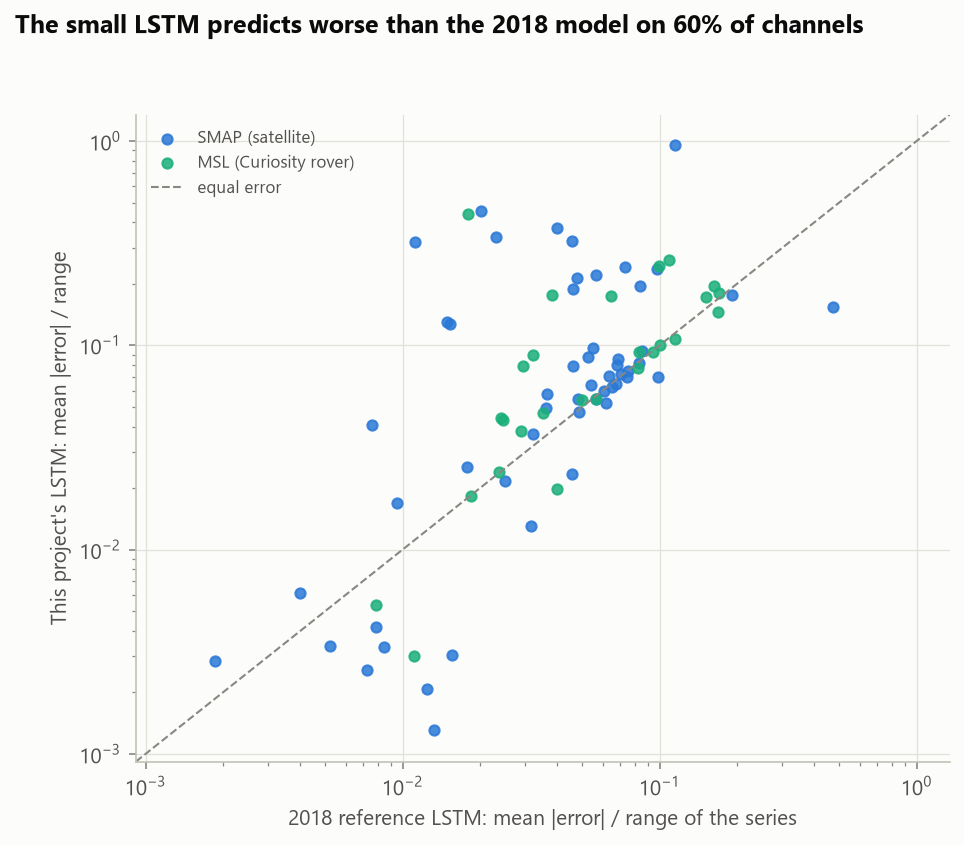

In [8]:
display(Image(FIG / '06_prediction_error.png'))

## 4. Event-level comparison

Every score goes through the same dynamic thresholding. Prediction errors (both LSTMs and the persistence residual
|y(t) - y(t-1)|) use the published settings as is. The other scores sit on a large offset, which the pruning rule
cannot handle (it compares sequence maxima by relative drop), so they are first shifted by their own median over the
previous 2,100 steps and the value-scale guards are switched off for them.

- The **2018 reference LSTM** leads on both spacecraft: F0.5 0.853 (SMAP) and 0.893 (MSL).
- The **small LSTM** reaches 0.777 and 0.792. Pooled over both spacecraft it trails the 2018 model by 0.083 (95% CI
  [-0.150, -0.012], Holm p = 0.039); within each spacecraft the gap is not significant after correction.
- A **one-line persistence residual** through the same thresholding gets 0.760 and 0.721, with the highest precision
  of any method (0.91 on SMAP) but under half the recall. Its difference from the small LSTM, +0.035 in the LSTM's
  favour (CI [-0.053, 0.130]), is not significant.
- The generic detectors trail by 0.21-0.44 F0.5 pooled (Holm p <= 0.004): rolling z-score 0.570, matrix profile
  0.514 (raw) and 0.487 (z-normalised), Isolation Forest 0.343. Matrix profile finds 84% of SMAP windows but raises
  66 false alarms. Isolation Forest flags nothing on the 16 channels with constant training values, because every
  window looks equally normal to a forest trained on identical windows.
- Uniform **random scores** get F0.5 0.094, and every other method is far above the random-placement null (the same
  detected sequences moved to random positions: about 0.14-0.18 F0.5, p = 0.001).

In [9]:
ev = pd.read_csv(RES / 'event_results.csv')
ev[ev.spacecraft != 'Total'][['method', 'spacecraft', 'tp', 'fp', 'fn', 'precision', 'recall', 'f05', 'f05_ci_low', 'f05_ci_high',
                             'null_f05_mean', 'null_p_value']]

,method,spacecraft,tp,fp,fn,precision,recall,f05,f05_ci_low,f05_ci_high,null_f05_mean,null_p_value
0,LSTM (this project),SMAP,51,14,17,0.785,0.750,0.777,0.708,0.848,0.172,9.990e-04
1,LSTM (this project),MSL,19,2,17,0.905,0.528,0.792,0.664,0.882,0.206,9.990e-04
3,LSTM (2018 reference run),SMAP,58,10,10,0.853,0.853,0.853,0.788,0.924,0.153,9.990e-04
4,LSTM (2018 reference run),MSL,25,1,11,0.962,0.694,0.893,0.817,0.957,0.229,9.990e-04
6,Persistence residual,SMAP,31,3,37,0.912,0.456,0.760,0.644,0.857,0.085,9.990e-04
7,Persistence residual,MSL,15,2,21,0.882,0.417,0.721,0.581,0.833,0.239,9.990e-04
9,Rolling z-score,SMAP,52,49,16,0.515,0.765,0.551,0.451,0.673,0.137,9.990e-04
10,Rolling z-score,MSL,21,12,15,0.636,0.583,0.625,0.484,0.767,0.289,9.990e-04
12,Isolation Forest,SMAP,33,87,35,0.275,0.485,0.301,0.233,0.381,0.128,9.990e-04
13,Isolation Forest,MSL,12,6,24,0.667,0.333,0.556,0.364,0.732,0.186,9.990e-04


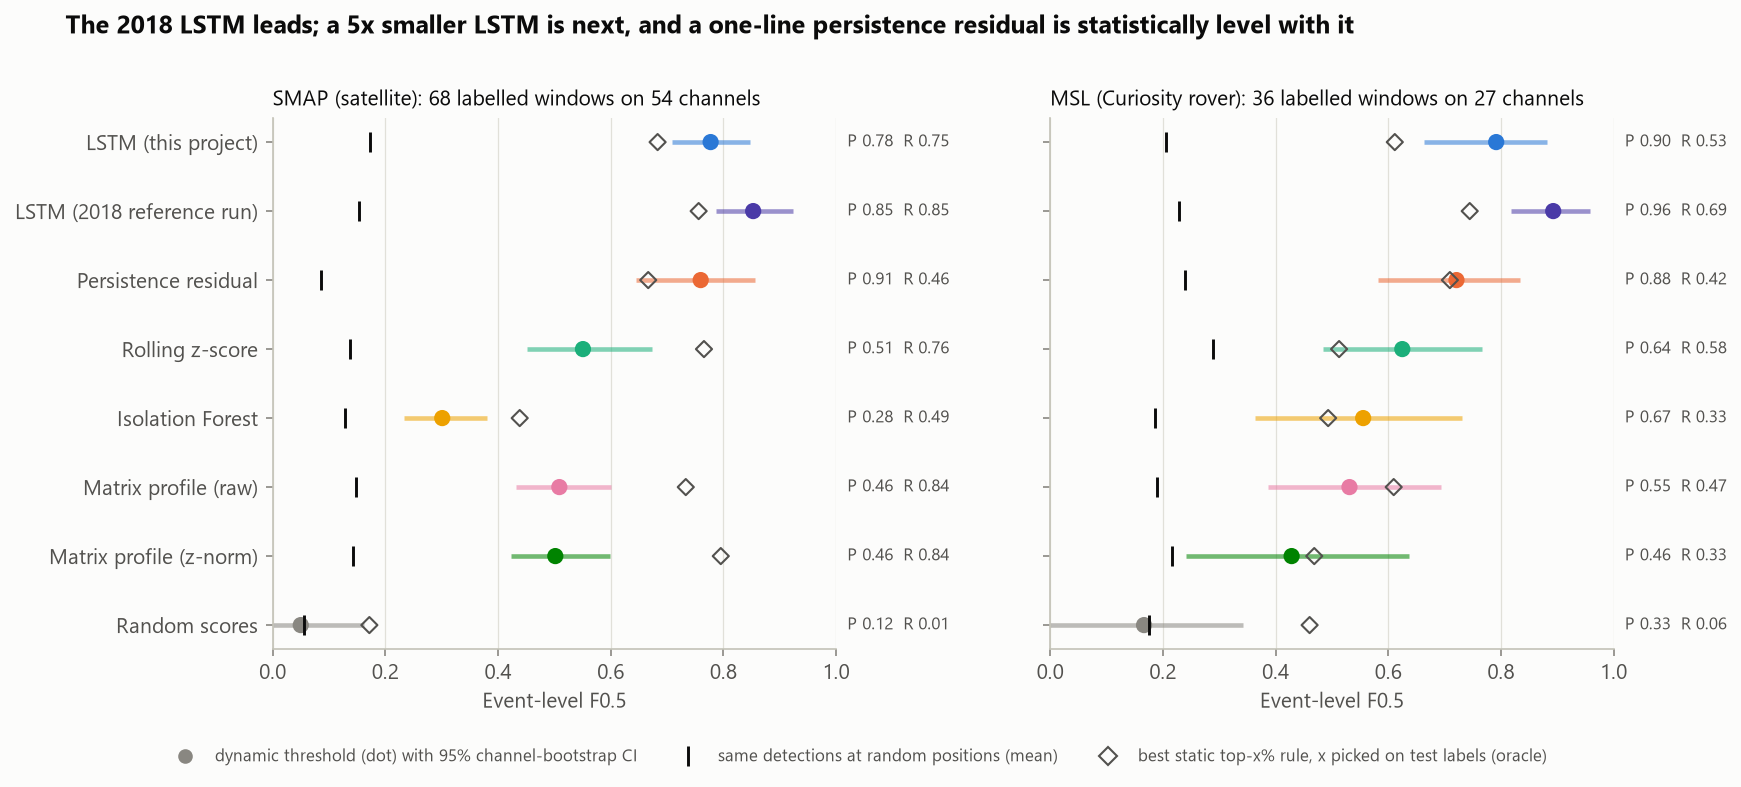

In [10]:
display(Image(FIG / '02_event_level_results.png'))

In [11]:
pd.read_csv(RES / 'significance.csv')

,spacecraft,comparison,diff_f05,ci_low,ci_high,p_value,p_holm
0,SMAP,LSTM (this project) - LSTM (2018 reference run),-0.076,-0.157,0.005,7.150e-02,0.143
1,SMAP,LSTM (this project) - Persistence residual,0.018,-0.084,0.133,7.425e-01,0.742
2,SMAP,LSTM (this project) - Rolling z-score,0.227,0.110,0.330,1.500e-03,0.004
3,SMAP,LSTM (this project) - Isolation Forest,0.476,0.383,0.566,5.000e-04,0.004
4,SMAP,LSTM (this project) - Matrix profile (raw),0.269,0.162,0.363,5.000e-04,0.004
5,SMAP,LSTM (this project) - Matrix profile (z-norm),0.276,0.155,0.388,5.000e-04,0.004
6,SMAP,LSTM (this project) - Random scores,0.727,0.613,0.831,5.000e-04,0.004
7,MSL,LSTM (this project) - LSTM (2018 reference run),-0.101,-0.235,0.002,6.250e-02,0.188
8,MSL,LSTM (this project) - Persistence residual,0.071,-0.078,0.224,3.505e-01,0.350
9,MSL,LSTM (this project) - Rolling z-score,0.167,-0.023,0.332,8.150e-02,0.188


## 5. What the detections look like

The three example channels are chosen by rule, not by hand: the first channel where every labelled window is found
without a false alarm and has the most windows (P-4), the channel with the most false alarms (G-7) and the first
channel where nothing is found (A-1). On A-1 the 85-step anomaly raises the smoothed error to 0.04, just under the
absolute 0.05 floor of the value-scale guards, so the window is never considered.

The timeline shows every channel. Labelled windows sit late in the test series: 88% of SMAP and 67% of MSL windows
start in the second half.

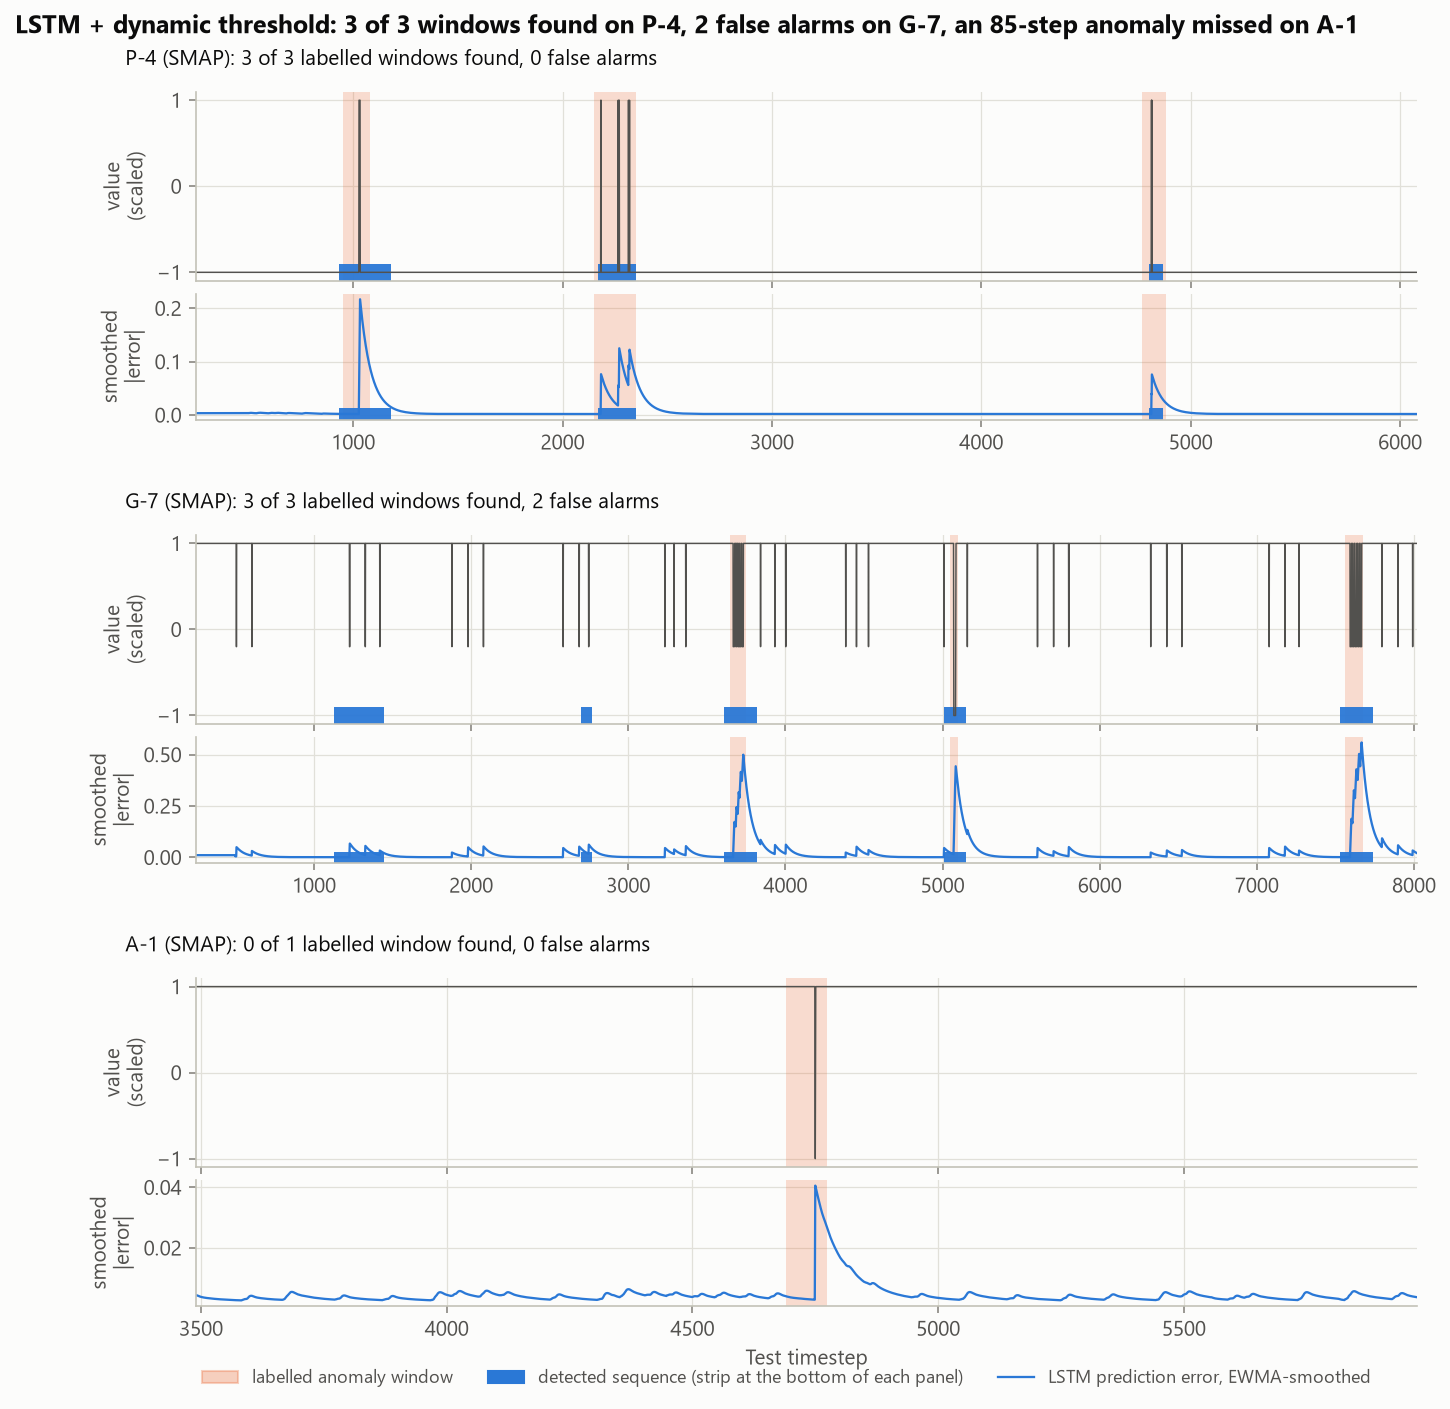

In [12]:
display(Image(FIG / '01_detection_examples.png'))

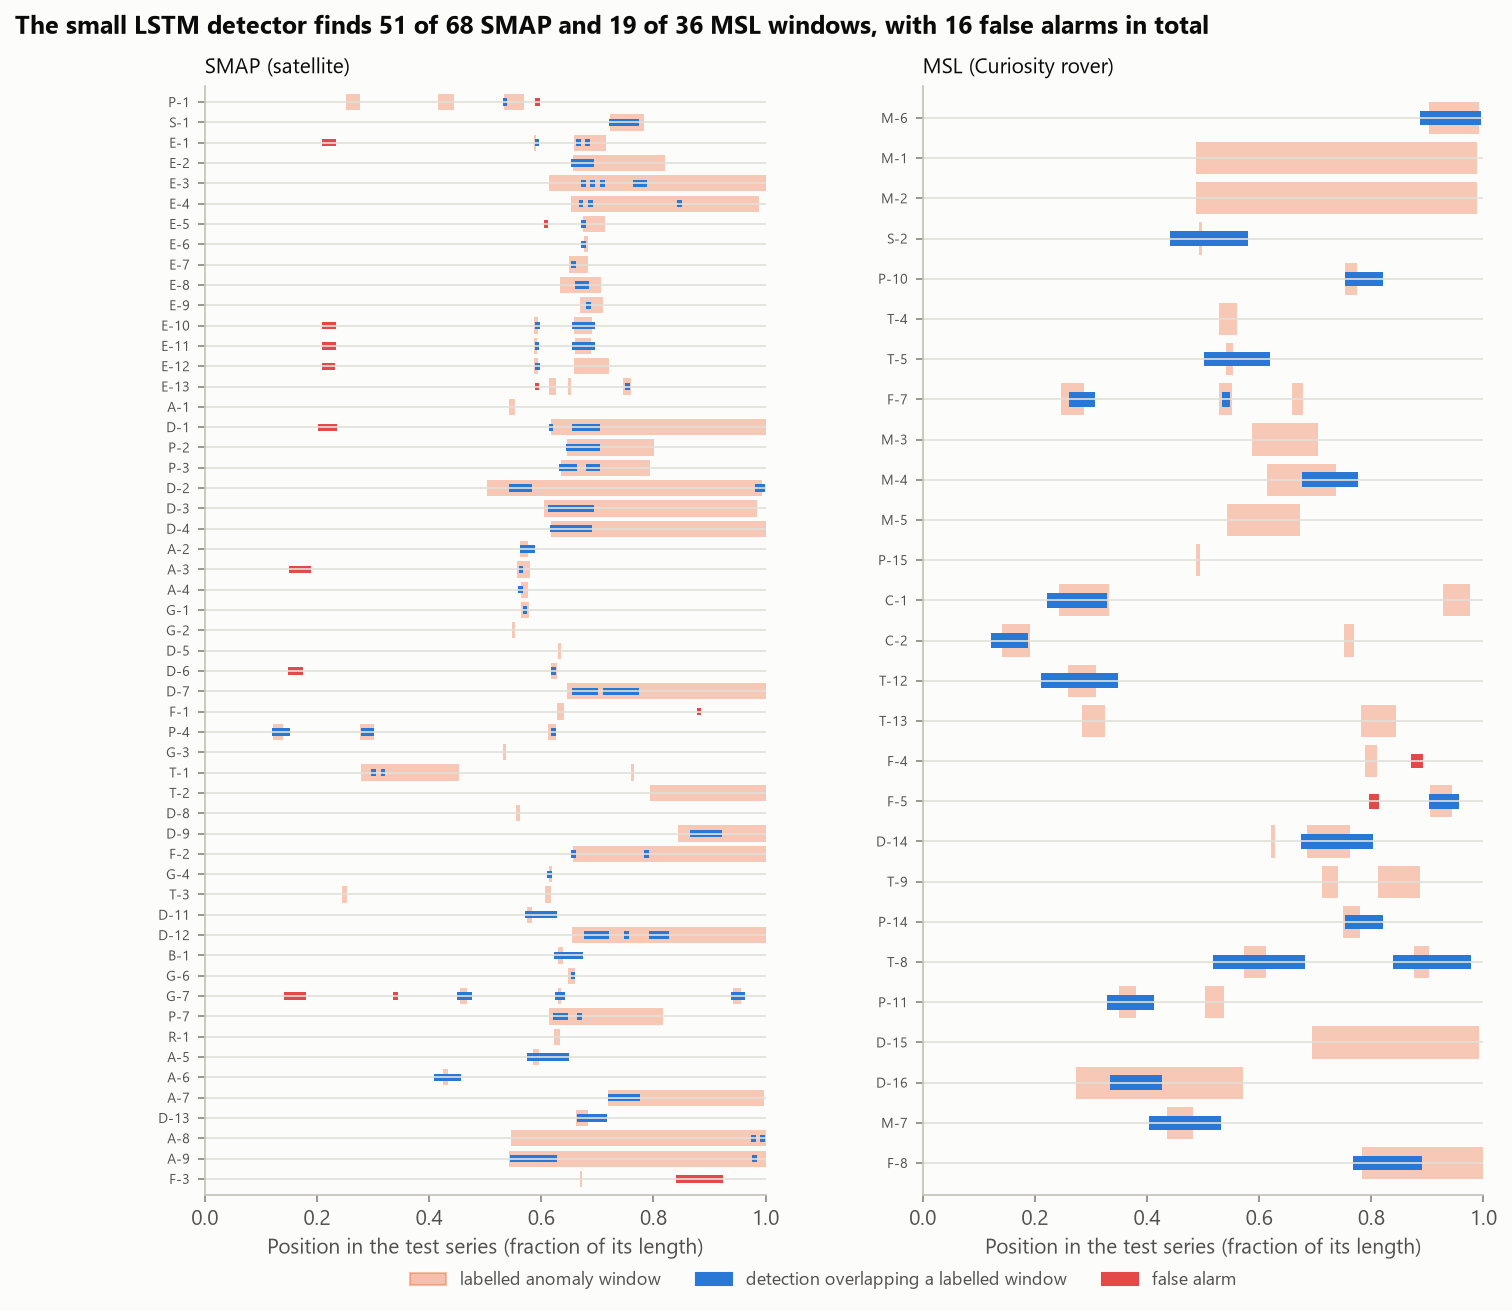

In [13]:
display(Image(FIG / '04_detection_timeline.png'))

## 6. Is it the score or the threshold?

To separate the two, every score is also run through a simple static rule: flag the top x% of smoothed scores in each
channel, buffer and group exactly like the detector, and pick the x that maximises F0.5 *on the test labels*. This is
an oracle, an optimistic upper bound. Under it the ranking changes: on SMAP the z-normalised matrix profile (0.795)
and rolling z-score (0.766) match or beat the 2018 LSTM (0.756) and clearly beat the small LSTM (0.683). Pooled over
both spacecraft the 2018 LSTM still leads (0.752), then matrix profile (0.692 / 0.685), persistence (0.676), rolling
z-score (0.673) and the small LSTM (0.631).

The dynamic threshold with the small LSTM (0.781 pooled) beats every oracle static rule, including the 2018 LSTM's.
So the dynamic threshold and pruning do much of the work, they suit prediction errors better than the other scores,
and the generic scores are better than their results in section 4 suggest.

In [14]:
orc = pd.read_csv(RES / 'oracle_static_threshold.csv')
best = orc.loc[orc.groupby(['method', 'spacecraft']).f05.idxmax()]
best[best.spacecraft != 'Total'][['method', 'spacecraft', 'top_frac', 'precision', 'recall', 'f05']].sort_values(['spacecraft', 'f05'], ascending=[False, False])

,method,spacecraft,top_frac,precision,recall,f05
243,Matrix profile (z-norm),SMAP,2.000e-03,0.817,0.721,0.795
123,Rolling z-score,SMAP,1.000e-03,0.778,0.721,0.766
45,LSTM (2018 reference run),SMAP,1.000e-03,0.766,0.721,0.756
207,Matrix profile (raw),SMAP,5.000e-03,0.759,0.647,0.733
3,LSTM (this project),SMAP,5.000e-04,0.707,0.603,0.683
78,Persistence residual,SMAP,2.000e-04,0.690,0.588,0.667
159,Isolation Forest,SMAP,5.000e-04,0.500,0.294,0.439
309,Random scores,SMAP,2.000e-01,0.143,0.956,0.172
58,LSTM (2018 reference run),MSL,2.000e-02,0.737,0.778,0.745
82,Persistence residual,MSL,5.000e-04,0.750,0.583,0.709


## 7. Which parts of the thresholding matter?

Same LSTM errors, one component removed at a time:

- **Pruning** is the critical piece: without it SMAP false alarms go from 14 to 126 and F0.5 from 0.777 to 0.347.
  MSL barely changes (0.792 to 0.799).
- **Value-scale guards** trade recall for precision: without them SMAP finds 59 instead of 51 windows but raises 22
  instead of 14 false alarms (F0.5 0.753).
- The **low-error search** (mirrored errors) adds 4 SMAP windows at no false-alarm cost.
- A **static threshold** (mean + 3 sd of the whole smoothed series) keeps precision but finds only 52% of windows (F0.5
  0.703 pooled).

In [15]:
pd.read_csv(RES / 'ablation.csv')[['variant', 'spacecraft', 'tp', 'fp', 'fn', 'precision', 'recall', 'f05']]

,variant,spacecraft,tp,fp,fn,precision,recall,f05
0,Published settings,SMAP,51,14,17,0.785,0.750,0.777
1,Published settings,MSL,19,2,17,0.905,0.528,0.792
2,Published settings,Total,70,16,34,0.814,0.673,0.781
3,No pruning,SMAP,55,126,13,0.304,0.809,0.347
4,No pruning,MSL,23,4,13,0.852,0.639,0.799
5,No pruning,Total,78,130,26,0.375,0.750,0.417
6,No value-scale guards,SMAP,59,22,9,0.728,0.868,0.753
7,No value-scale guards,MSL,19,2,17,0.905,0.528,0.792
8,No value-scale guards,Total,78,24,26,0.765,0.750,0.762
9,No low-error search,SMAP,47,14,21,0.770,0.691,0.753


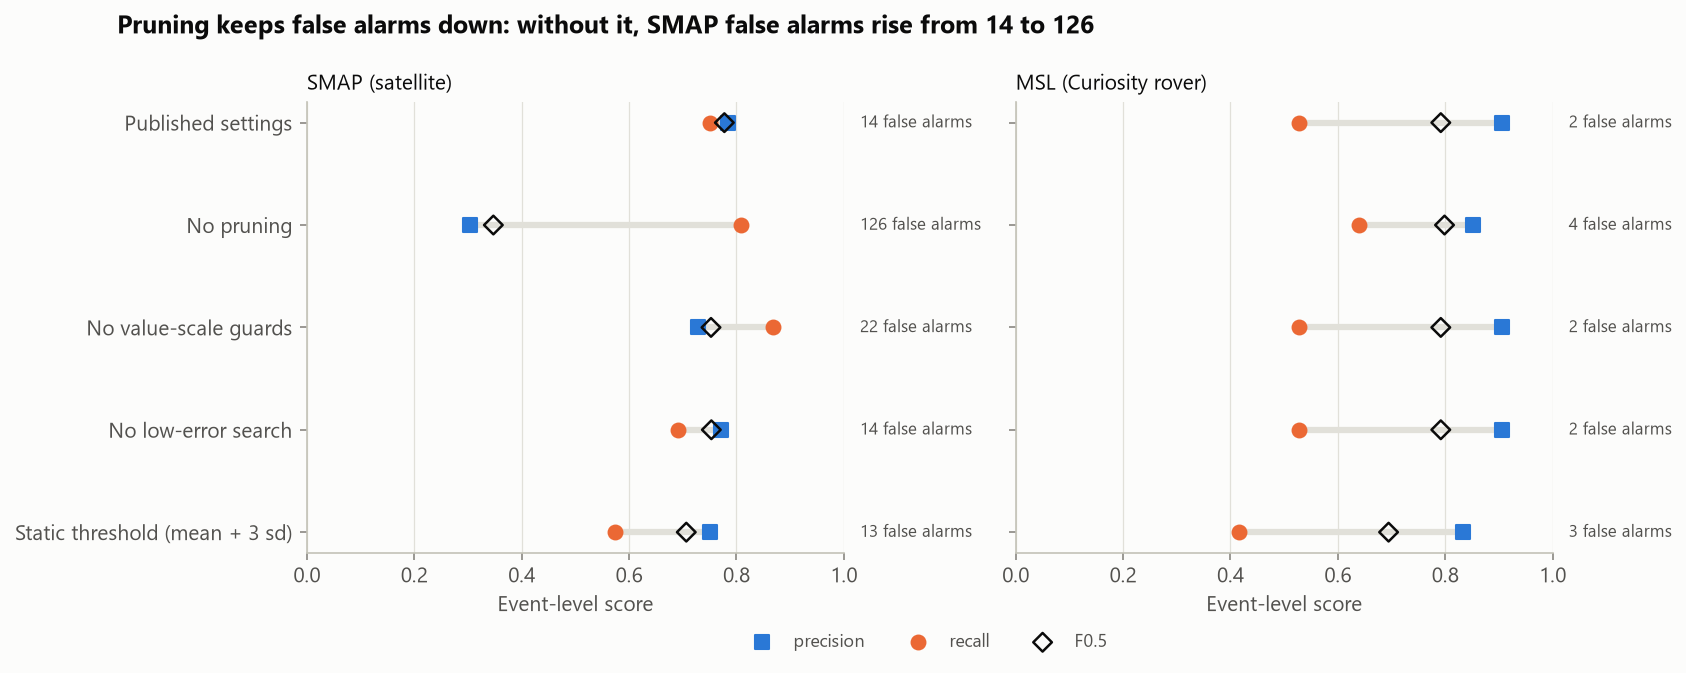

In [16]:
display(Image(FIG / '05_threshold_ablation.png'))

## 8. Why point-adjusted F1 inflates scores

Many deep-learning papers on SMAP and MSL report point-wise F1 after *point adjustment*: if any point inside a
labelled window is flagged, every point of that window counts as detected. The labelled windows here have a median
length of 121 steps and cover 12.5% of the test data, so one lucky point is worth on average 600 true positives.

With the threshold picked on the test labels, the protocol many papers use, **uniform random scores reach a
point-adjusted F1 of 0.954, against 0.962 for the small LSTM and 0.973 for the 2018 LSTM**. Without adjustment the same
random scores score 0.230, the F1 of flagging everything. Point adjustment also flatters the detector outputs: the
small LSTM's detections have point-wise F1 0.318 and point-adjusted F1 0.872. Event-level precision and recall do
not have this problem: random scores get F0.5 0.094 there.

In [17]:
pa = pd.read_csv(RES / 'point_adjust.csv')
pa[pa.spacecraft == 'Total'].merge(ev[ev.spacecraft == 'Total'][['method', 'f05']], on='method')[
    ['method', 'f05', 'detector_point_f1', 'detector_pa_f1', 'oracle_point_f1', 'oracle_pa_f1', 'flagged_share']]

,method,f05,detector_point_f1,detector_pa_f1,oracle_point_f1,oracle_pa_f1,flagged_share
0,LSTM (this project),0.781,0.318,0.872,0.343,0.962,0.045
1,LSTM (2018 reference run),0.865,0.303,0.877,0.324,0.973,0.041
2,Persistence residual,0.747,0.128,0.415,0.235,0.956,0.018
3,Rolling z-score,0.570,0.161,0.827,0.252,0.964,0.040
4,Isolation Forest,0.343,0.178,0.601,0.266,0.606,0.064
5,Matrix profile (raw),0.514,0.300,0.791,0.360,0.828,0.078
6,Matrix profile (z-norm),0.487,0.188,0.809,0.352,0.829,0.058
7,Random scores,0.094,0.011,0.153,0.230,0.954,0.005


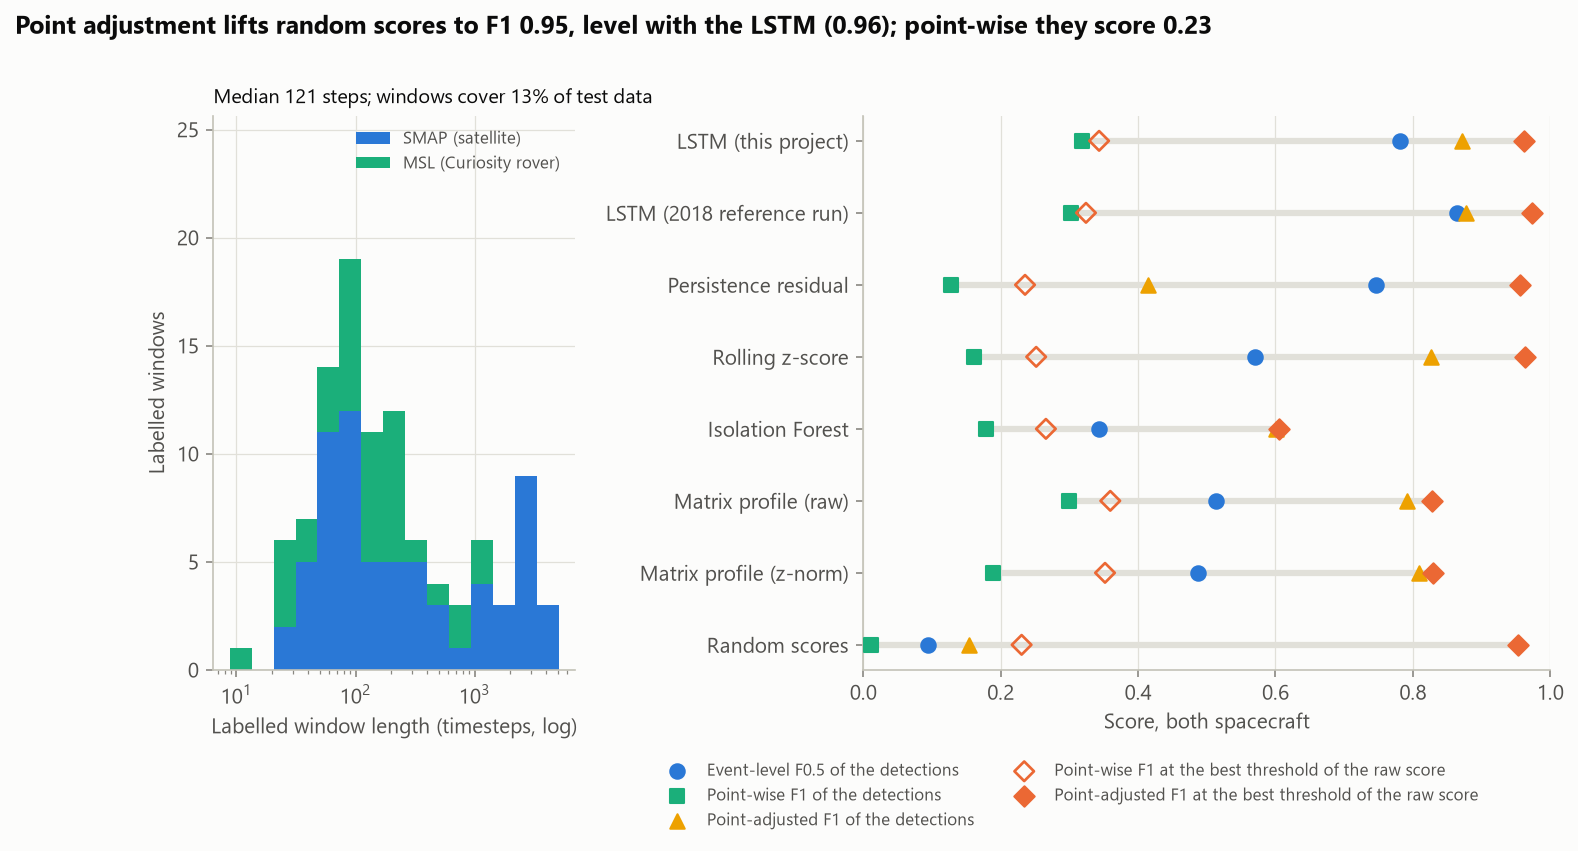

In [18]:
display(Image(FIG / '03_point_adjust_inflation.png'))

## 9. Point vs contextual anomalies

The dataset labels each window as a *point* anomaly (an out-of-range value) or a *contextual* one (a value that is
normal in range but not at that moment). Contextual anomalies are harder for every method: the 2018 LSTM finds 90% of
point anomalies and 65% of contextual ones; the rolling z-score finds 85% of point anomalies but only 49% of
contextual ones.

In [19]:
rc = pd.read_csv(RES / 'recall_by_class.csv')
rc[rc.spacecraft == 'Total'].pivot(index='method', columns='class', values='recall')

class,contextual,point
method,,
Isolation Forest,0.512,0.377
LSTM (2018 reference run),0.651,0.902
LSTM (this project),0.628,0.705
Matrix profile (raw),0.558,0.820
Matrix profile (z-norm),0.605,0.705
Persistence residual,0.326,0.525
Random scores,0.023,0.033
Rolling z-score,0.488,0.852


## 10. Takeaways

1. The dynamic thresholding reimplementation is exact: identical sequences on all 82 label rows of the 2018 run.
2. LSTM + dynamic thresholding is the best combination tested, but most of its event-level edge comes from the
   thresholding and pruning: a persistence residual through the same detector is statistically level with a small
   LSTM, and under an oracle static rule generic scores match the LSTMs on SMAP.
3. Model capacity matters: the 2018 model (5 times more parameters, 250-step input) beats the small model pooled.
4. Point-adjusted F1 cannot separate a good detector from random noise on this benchmark; event-level precision and
   recall can.

**Limitations.** One small LSTM configuration, trained once (no hyperparameter search, chronological early stopping
that fires early on flat channels). Baselines use one a priori history length (100 steps) and an adaptation of the
detector (median shift, guards off) for non-residual scores. 104 labelled windows make every confidence interval wide.
The reference run's thresholding skips error flattening on channel C-2 because its first anomaly is early, a choice
that uses label knowledge; it is kept for all methods to stay faithful to the published configuration.